In [1]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

##################################################################

c = cst.c.value # speed of light 
atomic_ratio = 2 
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 5/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = 0.013



def K_nr(eps_0):
    return (cst.hbar.value**2) / (15 *np.pi**2 * cst.m_e.value) * ((3 * np.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))

def beta_nr(eps_0):
    return (4 * np.pi * eps_0)/(cst.M_sun.value * c**2 * (K_nr(eps_0) * eps_0**(gamma - 1)**(1/gamma)))

def alpha_nr(eps_0):
    return R_0 / ((K_nr(eps_0) * eps_0**(1/gamma))**(1 - gamma))


def dH_dr(t, eqns, Gamma, Alpha, Beta, eps_0):
    Arr = [(-Alpha(eps_0) * eqns[1]** (1/Gamma) * eqns[0]) / t**2 , 
            Beta(eps_0) * t**2 * (eqns[1])**(1/Gamma)]
    return np.array(Arr)

##################################################################





In [2]:
X = np.array([0, 1]) # X = [M_bar,P_bar] <---- initial conditions 


r_s = np.linspace(0, 0.01,  10) # range of r values to use  


solution = sci.integrate.solve_ivp(dH_dr, y0 = X, t_span = [0.1,10000], vectorized = True, args = (gamma, alpha_nr, beta_nr, eps_0))

# 
M_bar, P_bar = solution

print(M_bar)

ValueError: too many values to unpack (expected 2)

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.000e-04 ...  4.991e+00  5.000e+00]
        y: [[ 1.000e+00  1.000e+00 ...  2.931e+34  4.815e+34]]
      sol: None
 t_events: None
 y_events: None
     nfev: 3014
     njev: 0
      nlu: 0


Text(0, 0.5, 'theta prime?')

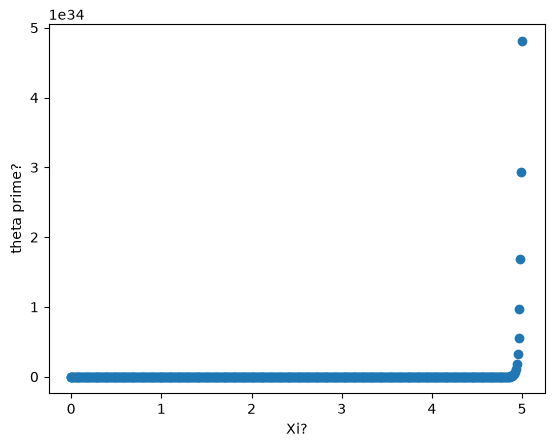

In [5]:
def Lane_Emden(t, eqns, n):
    coupling = np.array([eqns[0]/(t**2), -eqns[1]**n * t**2])
    return coupling



X = np.array([0]) # <---- initial conditions 

n = 5/2


def test_DE(t, initial_values, n):
    coupling = initial_values*t**n
    return coupling

solution = sci.integrate.solve_ivp(test_DE, y0 = [1], t_span = [0,5], max_step = 0.01,  args = (n,))


print(solution)

plt.scatter(solution.t, solution.y[0])
plt.xlabel('Xi?')
plt.ylabel('theta prime?')

In [126]:
help (sci.integrate.solve_ivp)

Help on function solve_ivp in module scipy.integrate._ivp.ivp:

solve_ivp(fun, t_span, y0, method='RK45', t_eval=None, dense_output=False, events=None, vectorized=False, args=None, **options)
    Solve an initial value problem for a system of ODEs.

    This function numerically integrates a system of ordinary differential
    equations given an initial value::

        dy / dt = f(t, y)
        y(t0) = y0

    Here t is a 1-D independent variable (time), y(t) is an
    N-D vector-valued function (state), and an N-D
    vector-valued function f(t, y) determines the differential equations.
    The goal is to find y(t) approximately satisfying the differential
    equations, given an initial value y(t0)=y0.

    Some of the solvers support integration in the complex domain, but note
    that for stiff ODE solvers, the right-hand side must be
    complex-differentiable (satisfy Cauchy-Riemann equations [11]_).
    To solve a problem in the complex domain, pass y0 with a complex data type.

/tmp/ipykernel_177819/3196557341.py:20: RuntimeWarning: invalid value encountered in scalar power
  coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])


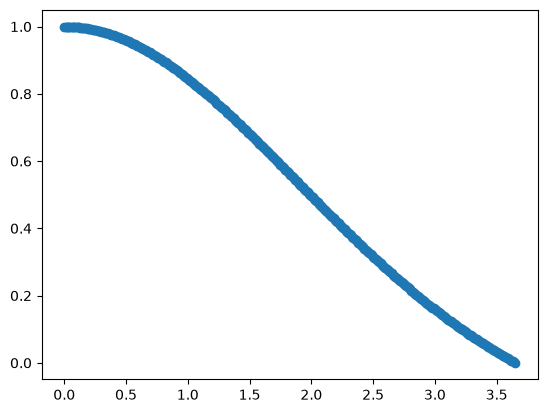

In [24]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

## Runga-kutta explicit method 
# fns = [u(theta(xi)), theta(xi)]

# Note: AI (Claude Sonnet 5.5) on low setting was used to assist in debugging the Runga-Kutta 4(5) 

X = np.array([0., 1.]) # these are initial conditions 

def Lane_Emden(t, fns, n):
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling

def RK4(f, initial_conditions, initial_radius, dxi, n_steps, n):
    con = np.zeros((n_steps + 1, 2))
    con[0] = initial_conditions # the initial conditions (must be an array)

    for i in range (0, n_steps):
        k_1 = f(initial_radius + i*dxi, con[i],  n )
        N_2 = con[i] + (k_1*dxi/2)
        k_2 = f((initial_radius + i*dxi+dxi/2), N_2, n )
        N_3 = con[i] + (k_2*dxi/2)
        k_3 = f( initial_radius + i*dxi+dxi/2, N_3,  n )
        N_4 = con[i] + (k_3*dxi)
        k_4 = f(initial_radius + i*dxi+dxi, N_4,  n )
        k = 1/6 * (k_1 + 2*k_2 + 2*k_3 + k_4)
        con[i+1] = (con[i] + dxi * k)
    return con 

steps = 2000
infintesimal = 0.01
order_n = 1
initial_radius = 0.00000000000000001 
ns = [3/2]


plt.figure()
for k in range(len(ns)):
    solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = ns[k])
    plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])

plt.show()

def zero_finder(
# solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = order_n)


# # # print(solved)

# plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])
# # # plt.scatter(solved[:1],solved[1:])

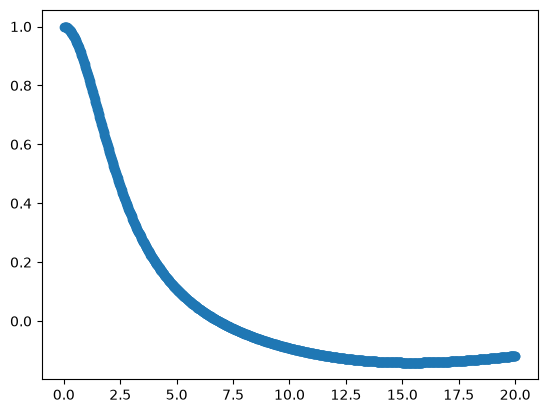

In [37]:
############################
#THIS IS SOMEONE ELSES CODE DO NOT USE. DO NOT MARK.
############################
n = 3

def runkutt(y,t,dt,n):
#Runge-Kutta 4th Order integrater as described in 
#An Introduction to Computational Physics, 2nd Edition by Tao Pang    
    c1 = np.zeros(2)
    c2 = np.zeros(2)
    c3 = np.zeros(2)
    c4 = np.zeros(2)
  
    c1 = g(y,t,n)
    
    c2 = y + dt*c1/2
    c2 = g(c2,t+dt/2,n)
    
    c3 = y + dt*c2/2
    c3 = g(c3,t+dt/2,n)
    
    c4 = y + dt*c3/2 
    c4 = g(c4,t+dt/2,n)
    
    return y + dt*(c1 + 2*(c2+c3) +c4)/6

def g(y,t,n):
#generates the vectors that act as the two 1st order differential equations
    v = np.zeros(2)
    
    v[0] = -y[1]/t**2
    v[1] = (y[0]**n)*t**2
    
    return v



def lane_emden_solver(n):
#only takes the polytropic index as input and returns the axis and polytrope
    dt = 20/1000 # the maximum is chosen at 20 to show the roots between n =4 and 5
    y1 = np.zeros(1000)
    y2 = np.zeros(1000)
    y  = np.zeros(2)
    y[0] = 1
    y[1] = 0
    
    y1[0] = y[0]
    y2[0] = y[1]
    t = np.zeros(1000)
    for i in range (1000):
        t[i]  = dt*(i+1)
        y     = runkutt(y,t[i],dt,n)
        y1[i] = y[0]
        y2[i] = y[1]
    return t,y1

xi,theta = lane_emden_solver(n)



plt.scatter(xi, theta)